In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

df = pd.read_csv("Mall_Customers.csv")

print("Dataset loaded successfully!")
print("\nFirst 5 rows:")
print(df.head())

print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

print("\nStatistical Description:")
print(df.describe())

print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

df = df.drop_duplicates()

df = df.dropna()

print("Shape after cleaning:", df.shape)

Dataset loaded successfully!

First 5 rows:
   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40
Dataset Shape: (200, 5)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4)

Selected Features:
   Age  Annual Income (k$)  Spending Score (1-100)
0   19                  15                      39
1   21                  15                      81
2   20                  16                       6
3   23                  16                      77
4   31                  17                      40

Feature Shape: (200, 3)


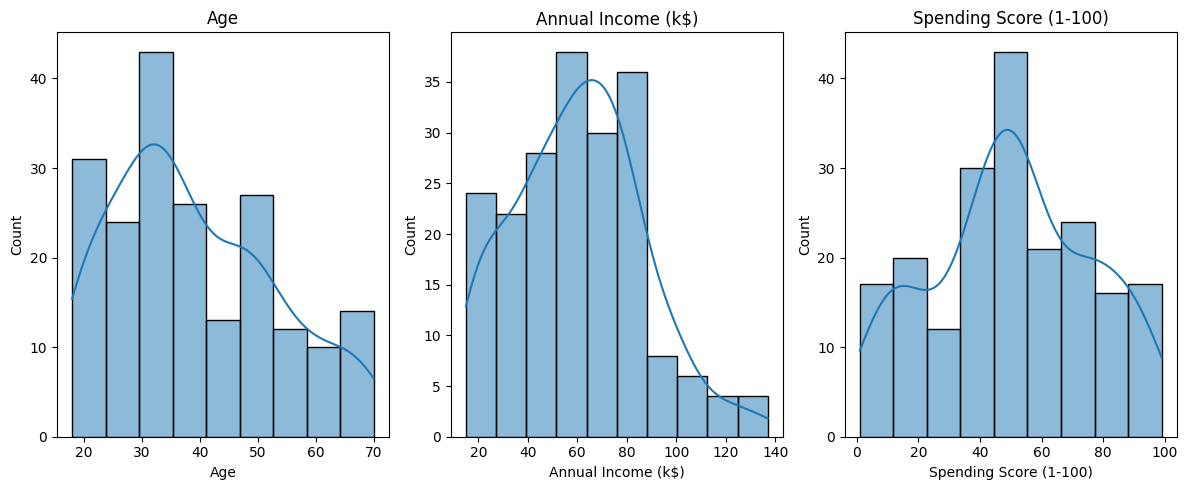

In [ ]:
features = ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']

X = df[features]

print("Selected Features:")
print(X.head())

print("\nFeature Shape:", X.shape)

plt.figure(figsize=(12, 5))

for i, column in enumerate(features):
    plt.subplot(1, 3, i+1)
    sns.histplot(df[column], kde=True)
    plt.title(column)

plt.tight_layout()
plt.show()

Scaled Dataset:
        Age  Annual Income (k$)  Spending Score (1-100)
0 -1.424569           -1.738999               -0.434801
1 -1.281035           -1.738999                1.195704
2 -1.352802           -1.700830               -1.715913
3 -1.137502           -1.700830                1.040418
4 -0.563369           -1.662660               -0.395980


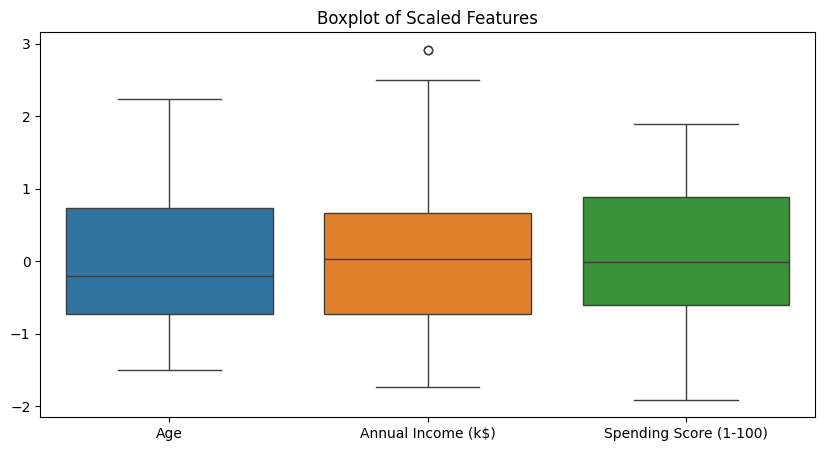

In [ ]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

X_scaled = pd.DataFrame(X_scaled, columns=features)

print("Scaled Dataset:")
print(X_scaled.head())

plt.figure(figsize=(10, 5))

sns.boxplot(data=X_scaled)

plt.title("Boxplot of Scaled Features")
plt.show()

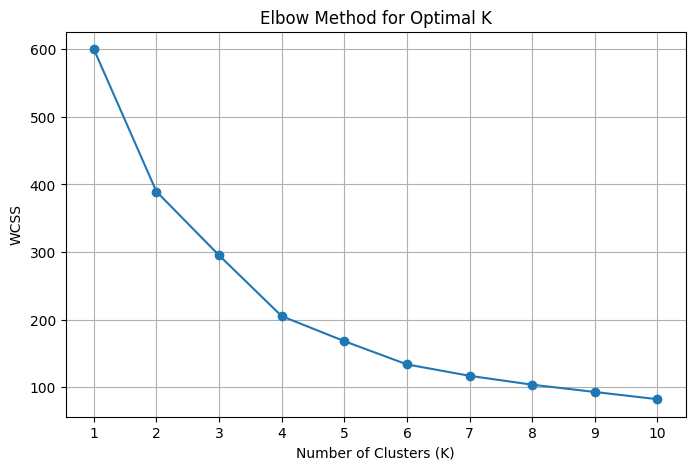

In [ ]:
wcss = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker='o')

plt.title('Elbow Method for Optimal K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS')
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

In [ ]:
silhouette_scores = []

for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)
    silhouette_scores.append(score)

    print(f"K = {k}, Silhouette Score = {score:.4f}")

K = 2, Silhouette Score = 0.3355
K = 3, Silhouette Score = 0.3578
K = 4, Silhouette Score = 0.4040
K = 5, Silhouette Score = 0.4166
K = 6, Silhouette Score = 0.4284
K = 7, Silhouette Score = 0.4172
K = 8, Silhouette Score = 0.4082
K = 9, Silhouette Score = 0.4177
K = 10, Silhouette Score = 0.4066


In [ ]:
optimal_k = 6

kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans.fit_predict(X_scaled)

df['KMeans_Cluster'] = kmeans_labels

print("K-Means Clustering Results:")
print(df[['Age', 'Annual Income (k$)',
          'Spending Score (1-100)',
          'KMeans_Cluster']].head(10))

#identify cluster centroids


centroids = kmeans.cluster_centers_

centroids_df = pd.DataFrame(
    scaler.inverse_transform(centroids),
    columns=features
)

print("K-Means Cluster Centroids:")
print(centroids_df)

K-Means Clustering Results:
   Age  Annual Income (k$)  Spending Score (1-100)  KMeans_Cluster
0   19                  15                      39               4
1   21                  15                      81               4
2   20                  16                       6               5
3   23                  16                      77               4
4   31                  17                      40               5
5   22                  17                      76               4
6   35                  18                       6               5
7   23                  18                      94               4
8   64                  19                       3               5
9   30                  19                      72               4
K-Means Cluster Centroids:
         Age  Annual Income (k$)  Spending Score (1-100)
0  56.333333           54.266667               49.066667
1  26.794872           57.102564               48.128205
2  41.939394           88.939394     

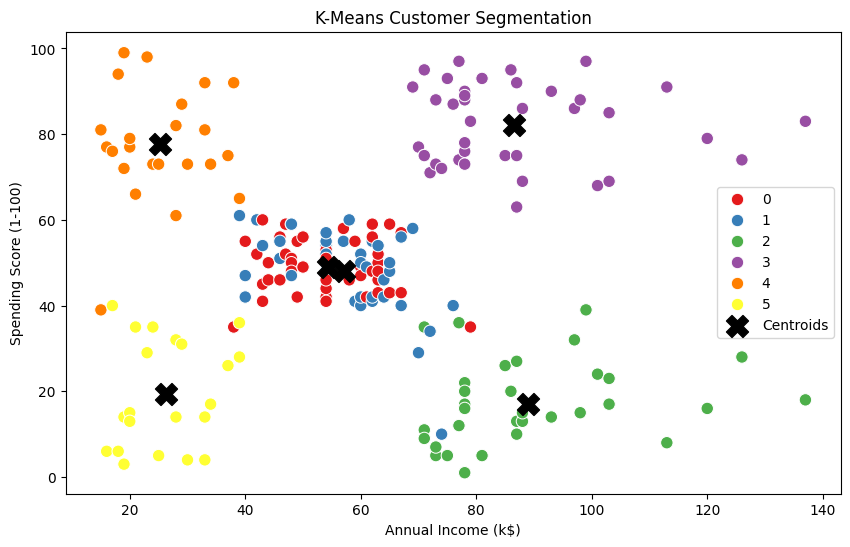

In [ ]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    x=df['Annual Income (k$)'],
    y=df['Spending Score (1-100)'],
    hue=df['KMeans_Cluster'],
    palette='Set1',
    s=80
)

centroids_original = scaler.inverse_transform(centroids)

plt.scatter(
    centroids_original[:, 1],
    centroids_original[:, 2],
    marker='X',
    s=250,
    color='black',
    label='Centroids'
)

plt.title('K-Means Customer Segmentation')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend()
plt.show()

In [ ]:
sil_score = silhouette_score(X_scaled, kmeans_labels)

db_score = davies_bouldin_score(X_scaled, kmeans_labels)

ch_score = calinski_harabasz_score(X_scaled, kmeans_labels)

print("K-Means Evaluation Metrics")
print("--------------------------------")
print("Silhouette Score:", round(sil_score, 4))
print("Davies-Bouldin Index:", round(db_score, 4))
print("Calinski-Harabasz Index:", round(ch_score, 4))


for k in [4, 5, 6]:

    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)

    print("\nNumber of Clusters:", k)
    print("Silhouette Score:",
          round(silhouette_score(X_scaled, labels), 4))

    print("Davies-Bouldin Index:",
          round(davies_bouldin_score(X_scaled, labels), 4))

    print("Calinski-Harabasz Index:",
          round(calinski_harabasz_score(X_scaled, labels), 4))

K-Means Evaluation Metrics
--------------------------------
Silhouette Score: 0.4284
Davies-Bouldin Index: 0.8254
Calinski-Harabasz Index: 135.1021

Number of Clusters: 4
Silhouette Score: 0.404
Davies-Bouldin Index: 0.9308
Calinski-Harabasz Index: 125.6764

Number of Clusters: 5
Silhouette Score: 0.4166
Davies-Bouldin Index: 0.8746
Calinski-Harabasz Index: 125.1009

Number of Clusters: 6
Silhouette Score: 0.4284
Davies-Bouldin Index: 0.8254
Calinski-Harabasz Index: 135.1021


K-Mediods


In [ ]:
!pip install scikit-learn-extra

from sklearn_extra.cluster import KMedoids

from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 819.0/819.0 kB 10.3 MB/s  0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for scikit-learn-extra: filename=scikit_learn_extra-0.3.0-cp313-cp313-linux_x86_64.whl size=2156383 sha256=55c81e5653b9cc5fecfe3a7b14c5c588cfc3f74c420e3658f233d6ac226e11c3
  Stored in directory: /root/.cache/pip/wheels/17/4b/b8/6b6711681d0981b110c9cc91ad6d1ebd88adf1547e1da301fc
Successfully built scikit-learn-extra


In [ ]:
kmedoids = KMedoids(
    n_clusters=6,
    metric='euclidean',
    method='alternate',
    random_state=42
)

kmedoids_labels = kmedoids.fit_predict(X_scaled)

df['KMedoids_Cluster'] = kmedoids_labels

print("K-Medoids Clustering Results:")
print(df[['Age', 'Annual Income (k$)',
          'Spending Score (1-100)',
          'KMedoids_Cluster']].head(10))


medoid_indices = kmedoids.medoid_indices_

medoids = X.iloc[medoid_indices]

print("K-Medoids Cluster Medoids:")
print(medoids)

K-Medoids Clustering Results:
   Age  Annual Income (k$)  Spending Score (1-100)  KMedoids_Cluster
0   19                  15                      39                 4
1   21                  15                      81                 4
2   20                  16                       6                 1
3   23                  16                      77                 4
4   31                  17                      40                 4
5   22                  17                      76                 4
6   35                  18                       6                 0
7   23                  18                      94                 4
8   64                  19                       3                 0
9   30                  19                      72                 4
K-Medoids Cluster Medoids:
     Age  Annual Income (k$)  Spending Score (1-100)
59    53                  46                      46
75    26                  54                      54
168   36                 

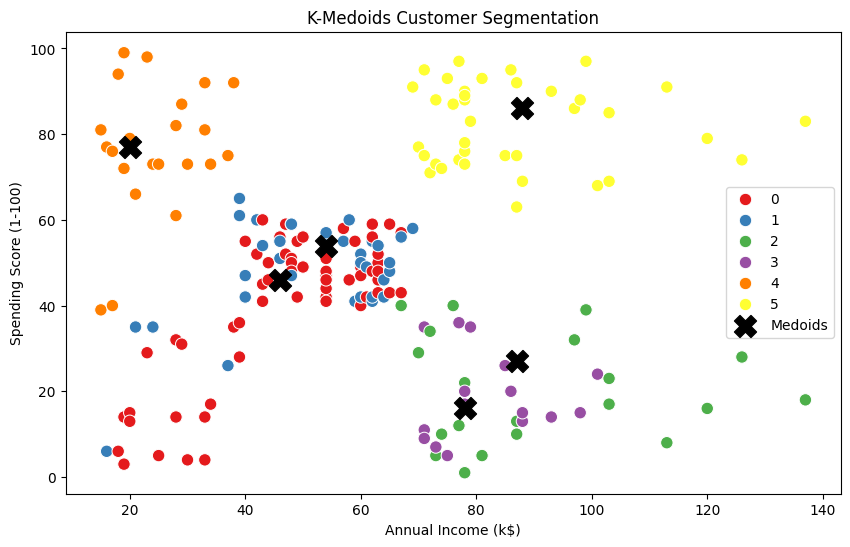

In [ ]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    x=df['Annual Income (k$)'],
    y=df['Spending Score (1-100)'],
    hue=df['KMedoids_Cluster'],
    palette='Set1',
    s=80
)

plt.scatter(
    medoids['Annual Income (k$)'],
    medoids['Spending Score (1-100)'],
    marker='X',
    s=250,
    color='black',
    label='Medoids'
)

plt.title('K-Medoids Customer Segmentation')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend()
plt.show()

In [ ]:
sil_kmedoids = silhouette_score(
    X_scaled, kmedoids_labels
)

db_kmedoids = davies_bouldin_score(
    X_scaled, kmedoids_labels
)

ch_kmedoids = calinski_harabasz_score(
    X_scaled, kmedoids_labels
)

print("K-Medoids Evaluation Metrics")
print("--------------------------------")

print("Silhouette Score:",
      round(sil_kmedoids, 4))

print("Davies-Bouldin Index:",
      round(db_kmedoids, 4))

print("Calinski-Harabasz Index:",
      round(ch_kmedoids, 4))

K-Medoids Evaluation Metrics
--------------------------------
Silhouette Score: 0.3538
Davies-Bouldin Index: 1.033
Calinski-Harabasz Index: 106.1677


In [ ]:


# Calculate K-Means metrics
kmeans_sil = silhouette_score(X_scaled, kmeans_labels)
kmeans_db = davies_bouldin_score(X_scaled, kmeans_labels)
kmeans_ch = calinski_harabasz_score(X_scaled, kmeans_labels)

# Calculate K-Medoids metrics
kmedoids_sil = silhouette_score(X_scaled, kmedoids_labels)
kmedoids_db = davies_bouldin_score(X_scaled, kmedoids_labels)
kmedoids_ch = calinski_harabasz_score(X_scaled, kmedoids_labels)

# Create comparison table
comparison = pd.DataFrame({
    'Algorithm': ['K-Means', 'K-Medoids'],
    'Silhouette Score': [kmeans_sil, kmedoids_sil],
    'Davies-Bouldin Index': [kmeans_db, kmedoids_db],
    'Calinski-Harabasz Index': [kmeans_ch, kmedoids_ch]
})

print("K-Means vs K-Medoids Comparison")
print(comparison.round(4))

K-Means vs K-Medoids Comparison
   Algorithm  Silhouette Score  Davies-Bouldin Index  Calinski-Harabasz Index
0    K-Means            0.4284                0.8254                 135.1021
1  K-Medoids            0.3538                1.0330                 106.1677


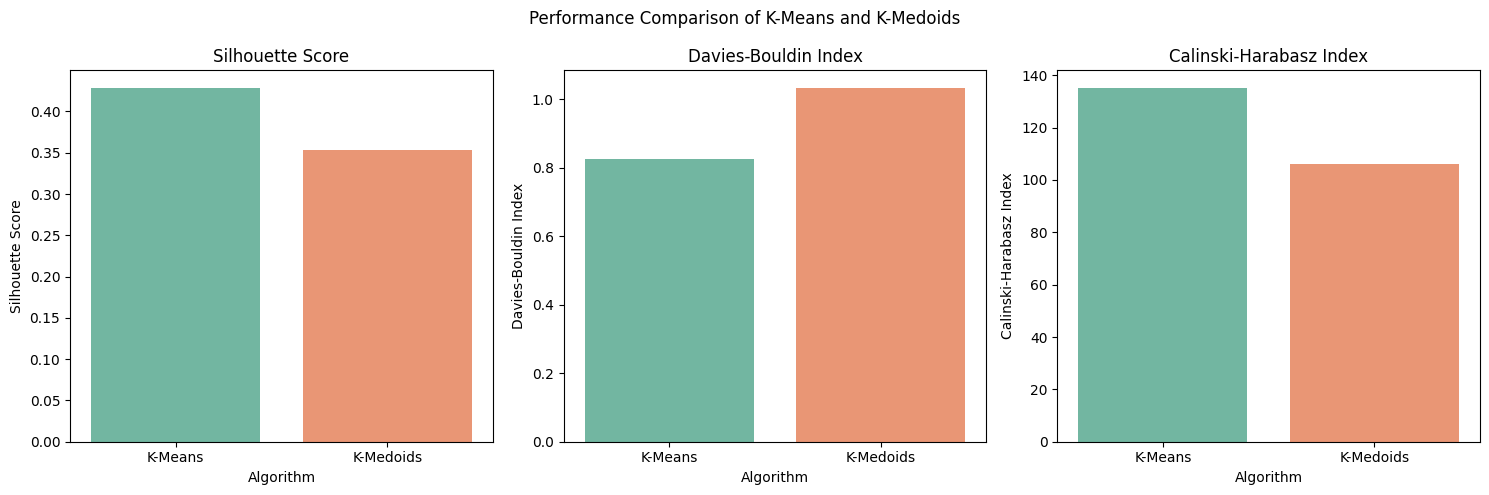

In [ ]:
metrics = ['Silhouette Score',
           'Davies-Bouldin Index',
           'Calinski-Harabasz Index']

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for i, metric in enumerate(metrics):

    sns.barplot(
        data=comparison,
        x='Algorithm',
        y=metric,
        ax=axes[i],
        hue='Algorithm',
        palette='Set2',
        legend=False
    )

    axes[i].set_title(metric)

plt.suptitle('Performance Comparison of K-Means and K-Medoids')
plt.tight_layout()
plt.show()

In [ ]:
print("K-Means Cluster Sizes:")
print(df['KMeans_Cluster'].value_counts().sort_index())

print("\nK-Medoids Cluster Sizes:")
print(df['KMedoids_Cluster'].value_counts().sort_index())

print("K-Means Centroids:")
print(centroids_df.round(2))

print("\nK-Medoids Medoids:")
print(medoids)

K-Means Cluster Sizes:
KMeans_Cluster
0    45
1    39
2    33
3    39
4    23
5    21
Name: count, dtype: int64

K-Medoids Cluster Sizes:
KMedoids_Cluster
0    62
1    37
2    21
3    18
4    23
5    39
Name: count, dtype: int64
K-Means Centroids:
     Age  Annual Income (k$)  Spending Score (1-100)
0  56.33               54.27                   49.07
1  26.79               57.10                   48.13
2  41.94               88.94                   16.97
3  32.69               86.54                   82.13
4  25.00               25.26                   77.61
5  45.52               26.29                   19.38

K-Medoids Medoids:
     Age  Annual Income (k$)  Spending Score (1-100)
59    53                  46                      46
75    26                  54                      54
168   36                  87                      27
154   47                  78                      16
13    24                  20                      77
175   30                  88               


K-Means:
1. Uses mean values as cluster centroids.
2. Sensitive to outliers.
3. Extreme values can shift centroids.

K-Medoids:
1. Uses actual data points as medoids.
2. More robust to outliers than K-Means.
3. Medoids are less affected by extreme observations.


CONCLUSION:

K-Means and K-Medoids clustering algorithms were
implemented on the Mall Customer Segmentation dataset.

The optimal number of clusters was selected as 6
using the Elbow Method and Silhouette Score analysis.

Both algorithms were evaluated using Silhouette Score,
Davies-Bouldin Index and Calinski-Harabasz Index.

K-Means achieved better clustering performance
than K-Medoids based on all three evaluation metrics.

Therefore, K-Means was found to be more suitable
for this particular dataset.
